# AllSides media-bias types, scored by Jev on 3,000 texts

750 random stories from the `test` split × 4 texts each: the left, centre and right source
articles (labelled by slot) and the LLM neutral summary (unlabelled). 3,000 texts in total.

Each text received **one request carrying 18 questions**, answered independently:
- **12 presence checks** (yes/no probability), one per AllSides type observable in a single text:
  spin, sensationalism, loaded words, subjective adjectives, opinion as fact, unsubstantiated
  claims, unattributed sources, mudslinging, mind reading, negativity, one-sidedness, flawed logic.
- **5 direction questions** (Choice): whose vocabulary; which side the slant favours; whose
  viewpoint comes first; which side is attacked; elite vs populist.
- **`outlet_style`**, the ideology question from the earlier Jev run, for comparison.

Not covered, because a single text can't show them: story choice, story placement, photo bias, and
omission (which needs the three articles compared side by side).

In [1]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix
J = Path("/root/ANLP/ANLP-Project/jev")
R = [json.loads(l) for l in open(J / "results/bias_types.jsonl")]
PRES = ["spin", "sensationalism", "loaded_words", "subjective_adjectives", "opinion_as_fact", "unsubstantiated",
        "unattributed_sources", "mudslinging", "mind_reading", "negativity", "one_sided", "flawed_logic"]
DIR = {"word_choice_side": ["left", "right", "neither"], "slant_side": ["left", "right", "neither"],
       "viewpoint_first_side": ["left", "right", "neither"], "attack_target": ["left", "right", "none"],
       "elite_populist": ["elite", "populist", "neither"], "outlet_style": ["left", "centre", "right"]}
rows = []
for r in R:
    d = {k: r[k] for k in ("id", "story_id", "slot", "label", "publisher", "input_tokens")}
    d.update({q: r[q]["p"] for q in PRES})
    for q, opts in DIR.items():
        for o in opts: d[f"{q}:{o}"] = r[q]["p"].get(o, 0.0)
    rows.append(d)
df = pd.DataFrame(rows)
ORDER = ["left", "center", "right", "neutral"]
spend = json.loads((J / "results/spend.json").read_text())
print(f"{len(df)} texts, {df.story_id.nunique()} stories;", df.slot.value_counts().to_dict())
print(f"mean {df.input_tokens.mean():.0f} input tokens per text (18 questions);"
      f" this run ≈ ${df.input_tokens.sum() * 0.042 / 1e6:.3f}; ledger total ${spend['usd']}")

3000 texts, 750 stories; {'left': 750, 'center': 750, 'right': 750, 'neutral': 750}
mean 1516 input tokens per text (18 questions); this run ≈ $0.191; ledger total $1.1412


## 1. How often each bias type appears, by text type

Mean yes-probability. Higher means more of that bias.

In [2]:
pres = df.groupby("slot")[PRES].mean().reindex(ORDER).T
pres["partisan_mean"] = pres[["left", "right"]].mean(1)
pres["neutral_vs_centre"] = pres["neutral"] - pres["center"]
pres.round(3).sort_values("neutral_vs_centre")

/tmp/ipykernel_27320/3374198920.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  pres["partisan_mean"] = pres[["left", "right"]].mean(1)


slot,left,center,right,neutral,partisan_mean,neutral_vs_centre
one_sided,0.550,0.479,0.547,0.300,0.548,-0.179
sensationalism,0.202,0.114,0.132,0.077,0.167,-0.037
opinion_as_fact,0.357,0.225,0.230,0.201,0.294,-0.024
spin,0.458,0.326,0.359,0.304,0.409,-0.023
negativity,0.370,0.282,0.306,0.269,0.338,-0.012
flawed_logic,0.417,0.351,0.378,0.347,0.398,-0.004
subjective_adjectives,0.105,0.089,0.091,0.087,0.098,-0.002
mind_reading,0.378,0.275,0.276,0.279,0.327,0.004
loaded_words,0.271,0.216,0.256,0.236,0.264,0.019
unsubstantiated,0.669,0.649,0.670,0.680,0.670,0.031


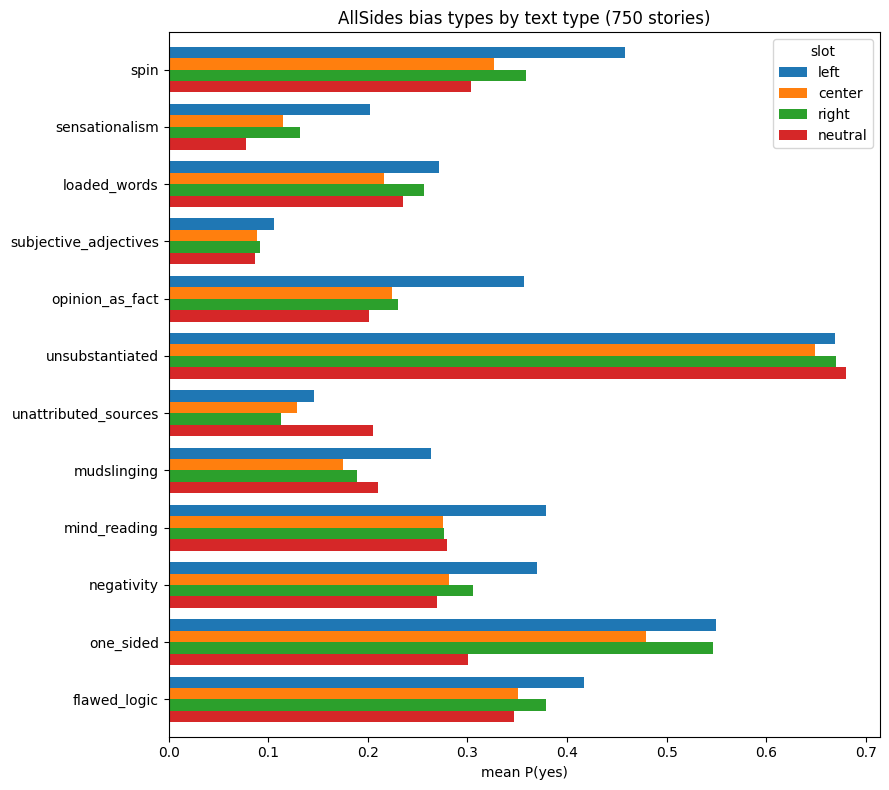

In [3]:
ax = pres[ORDER].plot.barh(figsize=(9, 8), width=0.8)
ax.set(xlabel="mean P(yes)", title="AllSides bias types by text type (750 stories)"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

In [4]:
# overall bias load: mean over the 12 presence checks
df["bias_load"] = df[PRES].mean(1)
load = df.groupby("slot").bias_load.describe().reindex(ORDER)[["mean", "25%", "50%", "75%"]]
# paired comparison within each story: is the neutral summary less biased than its own sources?
w = df.pivot(index="story_id", columns="slot", values="bias_load")
for s in ["left", "center", "right"]:
    load.loc[s, "neutral_lower_in_%_of_stories"] = (w.neutral < w[s]).mean() * 100
load.round(3)

/tmp/ipykernel_27320/3899809022.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  df["bias_load"] = df[PRES].mean(1)


,mean,25%,50%,75%,neutral_lower_in_%_of_stories
slot,,,,,
left,0.349,0.234,0.318,0.428,70.533
center,0.276,0.211,0.260,0.328,51.600
right,0.296,0.216,0.273,0.357,59.200
neutral,0.266,0.214,0.260,0.316,NaN


## 2. Direction questions against the true label (labelled articles only)

In [5]:
lab = df[df.slot != "neutral"].copy(); lab["label"] = lab.label.astype(int)
out = []
for q, opts in DIR.items():
    tab = lab.groupby("slot")[[f"{q}:{o}" for o in opts]].mean().reindex(["left", "center", "right"])
    tab.columns = opts
    out.append(tab.assign(question=q).set_index("question", append=True))
pd.concat(out).round(3)

,,left,right,neither,none,elite,populist,centre
slot,question,,,,,,,
left,word_choice_side,0.148,0.086,0.766,NaN,NaN,NaN,NaN
center,word_choice_side,0.080,0.123,0.797,NaN,NaN,NaN,NaN
right,word_choice_side,0.078,0.180,0.742,NaN,NaN,NaN,NaN
left,slant_side,0.492,0.145,0.363,NaN,NaN,NaN,NaN
center,slant_side,0.383,0.218,0.399,NaN,NaN,NaN,NaN
right,slant_side,0.301,0.324,0.375,NaN,NaN,NaN,NaN
left,viewpoint_first_side,0.374,0.169,0.457,NaN,NaN,NaN,NaN
center,viewpoint_first_side,0.289,0.272,0.440,NaN,NaN,NaN,NaN
right,viewpoint_first_side,0.239,0.340,0.421,NaN,NaN,NaN,NaN


In [6]:
# each directional question used as a stand-alone 3-way classifier
def as_pred(q):
    if q == "outlet_style":
        P = lab[[f"{q}:left", f"{q}:centre", f"{q}:right"]].values
    else:
        o = DIR[q]; P = lab[[f"{q}:{o[0]}", f"{q}:{o[2]}", f"{q}:{o[1]}"]].values   # left, neither->centre, right
    return P.argmax(1), P
y = lab.label.values; res = []
for q in ["outlet_style", "word_choice_side", "slant_side", "viewpoint_first_side", "attack_target"]:
    pred, P = as_pred(q)
    res.append({"question": q, "accuracy": (pred == y).mean(), "macro_f1": f1_score(y, pred, average="macro"),
                "recall_L": (pred[y == 0] == 0).mean(), "recall_C": (pred[y == 1] == 1).mean(),
                "recall_R": (pred[y == 2] == 2).mean()})
pd.DataFrame(res).round(4)

,question,accuracy,macro_f1,recall_L,recall_C,recall_R
0,outlet_style,0.4604,0.4345,0.3413,0.8107,0.2293
1,word_choice_side,0.3813,0.3154,0.1307,0.8573,0.1560
2,slant_side,0.4133,0.4109,0.5080,0.4147,0.3173
3,viewpoint_first_side,0.3867,0.3873,0.3627,0.4467,0.3507
4,attack_target,0.3240,0.2467,0.0427,0.7893,0.1400


## 3. All 17 bias signals combined

A logistic regression over every presence and direction probability, with story-grouped 5-fold
cross-validation so no story's articles appear in both train and test. This measures how much
ideology signal the AllSides features carry together.

In [7]:
from sklearn.model_selection import GroupKFold
feat_all = PRES + [c for c in df.columns if ":" in c and not c.startswith("outlet_style")]
def cv(feats):
    X = lab[feats].values
    clf = LogisticRegression(max_iter=2000, C=1.0)
    P = cross_val_predict(clf, X, y, cv=GroupKFold(5), groups=lab.story_id, method="predict_proba")
    p = P.argmax(1)
    return {"accuracy": (p == y).mean(), "macro_f1": f1_score(y, p, average="macro"),
            "auc_macro": roc_auc_score(y, P, multi_class="ovr", average="macro")}, p
rows = []
for name, feats in [("presence only (12)", PRES),
                    ("direction only", [c for c in feat_all if ":" in c]),
                    ("all bias signals (27 features)", feat_all),
                    ("all + outlet_style", feat_all + ["outlet_style:left", "outlet_style:centre", "outlet_style:right"])]:
    m, p = cv(feats); rows.append({"features": name, **m})
    if name.startswith("all +"): best_pred = p
pd.DataFrame(rows).round(4)

,features,accuracy,macro_f1,auc_macro
0,presence only (12),0.4582,0.4587,0.6418
1,direction only,0.4413,0.4402,0.6253
2,all bias signals (27 features),0.4822,0.4817,0.6731
3,all + outlet_style,0.5098,0.5104,0.7084


In [8]:
cm = confusion_matrix(y, best_pred, labels=[0, 1, 2])
print("confusion matrix, all signals + outlet_style (cross-validated):")
pd.DataFrame(cm, index=["true Left", "true Centre", "true Right"], columns=["pred Left", "pred Centre", "pred Right"])

confusion matrix, all signals + outlet_style (cross-validated):


,pred Left,pred Centre,pred Right
true Left,443,187,120
true Centre,187,350,213
true Right,121,275,354


In [9]:
# which signals separate the classes? one-vs-rest AUC per feature
auc = {}
for f in feat_all:
    auc[f] = {c: roc_auc_score((y == i).astype(int), lab[f]) for i, c in enumerate(["vs_Left", "vs_Centre", "vs_Right"])}
a = pd.DataFrame(auc).T
a["max_dev_from_0.5"] = (a - 0.5).abs().max(1)
a.sort_values("max_dev_from_0.5", ascending=False).head(12).round(3)

/tmp/ipykernel_27320/1459700528.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  a["max_dev_from_0.5"] = (a - 0.5).abs().max(1)


,vs_Left,vs_Centre,vs_Right,max_dev_from_0.5
opinion_as_fact,0.676,0.419,0.405,0.176
mind_reading,0.638,0.441,0.422,0.138
spin,0.629,0.407,0.464,0.129
slant_side:right,0.385,0.492,0.623,0.123
slant_side:left,0.615,0.496,0.389,0.115
sensationalism,0.610,0.409,0.481,0.110
viewpoint_first_side:left,0.598,0.481,0.421,0.098
negativity,0.591,0.431,0.477,0.091
viewpoint_first_side:right,0.410,0.498,0.591,0.091
one_sided,0.543,0.416,0.541,0.084


## 4. Neutral summaries: direction and ideology

In [10]:
neu = df[df.slot == "neutral"]
out = {}
for q in ["outlet_style", "word_choice_side", "slant_side", "viewpoint_first_side", "attack_target"]:
    opts = DIR[q]
    out[q] = {o: neu[f"{q}:{o}"].mean() for o in opts}
pd.DataFrame(out).T.round(3)

,left,centre,right,neither,none
outlet_style,0.111,0.835,0.053,NaN,NaN
word_choice_side,0.085,NaN,0.126,0.789,NaN
slant_side,0.396,NaN,0.177,0.427,NaN
viewpoint_first_side,0.283,NaN,0.261,0.456,NaN
attack_target,0.066,NaN,0.197,NaN,0.737


## Notes

- Presence probabilities are Jev's answers to one question per type, not calibrated rates. Compare
  them across text types; the absolute values are less meaningful.
- The labels are outlet-level. Where a direction question disagrees with the label, the article
  may genuinely be milder than its outlet.
- Omission bias isn't here. It needs the three articles of a story compared in one request.
- Raw answers (full distributions): `jev/results/bias_types.jsonl`.